# Immune subtypes of sepsis and 28 day mortality

BT3041 term project: Aditya Kumar (BE24B017), Darsh Balia (BE24B025), Harin Raam A (BE24B026), Pundru Bharath (BE24B034), Yaasir (BE24B043)

Data: GEO GSE65682 (479 sepsis patients).
To run: upload Patients.csv and Genes.csv, then Run all.

In [1]:
!pip install -q umap-learn gseapy

import os, warnings, urllib.request
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import fcluster
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, rand_score, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
import umap, gseapy

pd.set_option("display.width", 160)
SEED = 0

def find_file(name):
    for folder in ["/content", ".", "/content/data", "/content/drive/MyDrive"]:
        p = os.path.join(folder, name)
        if os.path.exists(p):
            return p
    return None

FILES = {n: find_file(n) for n in ["Patients.csv", "Genes.csv"]}
print(FILES)
missing = [n for n, p in FILES.items() if p is None]
assert not missing, f"Please upload these files first: {missing}"

BASE = "outputs"
FIG, RES = os.path.join(BASE, "figures"), os.path.join(BASE, "results")
for d in [FIG, RES]:
    os.makedirs(d, exist_ok=True)
print("outputs will be saved in", os.path.abspath(BASE))

{'Patients.csv': '/content/Patients.csv', 'Genes.csv': '/content/Genes.csv'}
outputs will be saved in /content/outputs


## Data acquisition


In [2]:
samples = pd.read_csv(FILES["Patients.csv"], index_col=0)
samples["group"] = samples["group"].replace("Sepsis_with_outcome", "Sepsis")
samples = samples.rename(columns={"sample_title": "title"})
genes = pd.read_csv(FILES["Genes.csv"], index_col=0)

print("samples:", samples.shape, "| genes x samples:", genes.shape)
print(samples.group.value_counts().to_string())
print("missing expression values:", int(genes.isna().sum().sum()))
print("same sample order in both files:", list(genes.columns) == list(samples.index))

samples: (802, 15) | genes x samples: (11519, 802)
group
Sepsis       479
Other_ICU    281
Healthy       42
missing expression values: 0
same sample order in both files: True


### Pathway gene sets

In [3]:
GMT = os.path.join(BASE, "h.all.v7.0.symbols.gmt")
if not os.path.exists(GMT):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/zqfang/GSEApy/master/tests/extdata/h.all.v7.0.symbols.gmt", GMT)

hallmark = {}
with open(GMT) as fh:
    for line in fh:
        parts = line.rstrip("\n").split("\t")
        hallmark[parts[0].replace("HALLMARK_", "")] = set(parts[2:])
print(len(hallmark), "Hallmark gene sets, e.g.", list(hallmark)[:3])

50 Hallmark gene sets, e.g. ['TNFA_SIGNALING_VIA_NFKB', 'HYPOXIA', 'CHOLESTEROL_HOMEOSTASIS']


## Preprocessing and quality control

**Aim:** check that all 802 arrays are on the same scale and flag any unusual samples before analysis.

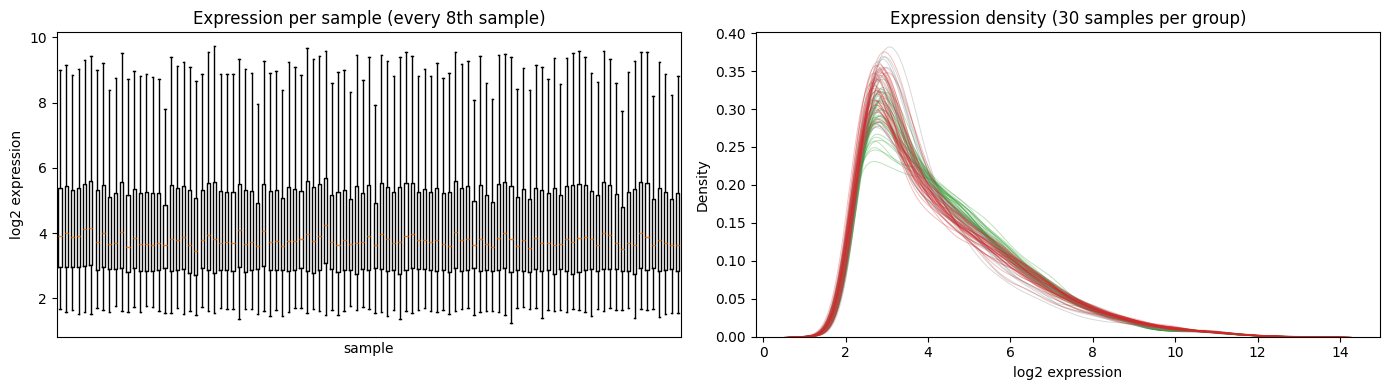

correlation with median array: min 0.756, median 0.960
9 samples flagged (z < -4); all still correlate > 0.76, so they are kept


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = samples.sort_values("group").index
ax[0].boxplot(genes[order[::8]].values, showfliers=False)
ax[0].set_title("Expression per sample (every 8th sample)")
ax[0].set_xlabel("sample"); ax[0].set_ylabel("log2 expression"); ax[0].set_xticks([])
for grp, col in zip(["Healthy", "Other_ICU", "Sepsis"], ["tab:green", "tab:grey", "tab:red"]):
    for s in samples.index[samples.group == grp][:30]:
        sns.kdeplot(genes[s], ax=ax[1], color=col, alpha=0.3, lw=0.7)
ax[1].set_title("Expression density (30 samples per group)")
ax[1].set_xlabel("log2 expression")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "02_qc_distributions.png"), dpi=150); plt.show()

# Samples that correlate unusually poorly with the median array
corr_to_median = genes.corrwith(genes.median(axis=1))
z = (corr_to_median - corr_to_median.mean()) / corr_to_median.std()
outliers = z[z < -4].index.tolist()
print(f"correlation with median array: min {corr_to_median.min():.3f}, median {corr_to_median.median():.3f}")
print(f"{len(outliers)} samples flagged (z < -4); all still correlate > {corr_to_median[outliers].min():.2f}, so they are kept")

## Cohort description

**Aim:** describe the patients. Age, sex and cohort are tested together in one model in Q2, so only age gets a test here.

In [5]:
sep = samples[samples.group == "Sepsis"].copy()
sep["died"] = sep.mortality_event_28days.astype(int)
sep["outcome"] = sep.died.map({0: "Survived", 1: "Died"})

def describe(d):
    return pd.Series({"n": len(d),
                      "age, mean (SD)": f"{d.age.mean():.1f} ({d.age.std():.1f})",
                      "male, %": round(100 * (d.gender == "male").mean(), 1),
                      "diabetes, % of known": round(100 * (d.diabetes_mellitus == "DM").sum()
                                                    / d.diabetes_mellitus.notna().sum(), 1),
                      "discovery cohort, %": round(100 * (d.endotype_cohort == "discovery").mean(), 1)})

table1 = sep.groupby("outcome").apply(describe).T
table1["All sepsis"] = describe(sep)
print(table1.to_string())
print(f"\n28-day deaths: {sep.died.sum()} of {len(sep)} ({100*sep.died.mean():.1f}%)")
table1.to_csv(os.path.join(RES, "table1_cohort.csv"))

t, p = stats.ttest_ind(sep.age[sep.died == 1], sep.age[sep.died == 0], equal_var=False)
print(f"Age, died vs survived: Welch t = {t:.2f}, p = {p:.4f}")

outcome                      Died     Survived   All sepsis
n                             114          365          479
age, mean (SD)        64.5 (13.6)  59.9 (15.0)  61.0 (14.8)
male, %                      59.6         55.9         56.8
diabetes, % of known         24.4         22.3         22.8
discovery cohort, %          60.5         53.2         54.9

28-day deaths: 114 of 479 (23.8%)
Age, died vs survived: Welch t = 3.10, p = 0.0022


## Q1: Do sepsis patients form natural gene expression subgroups, and can clustering recover the published Mars endotypes?


### Structure of all 802 samples (PCA, UMAP)

variance explained PC1-5: [0.197 0.171 0.094 0.065 0.043] | PC1+PC2: 0.367


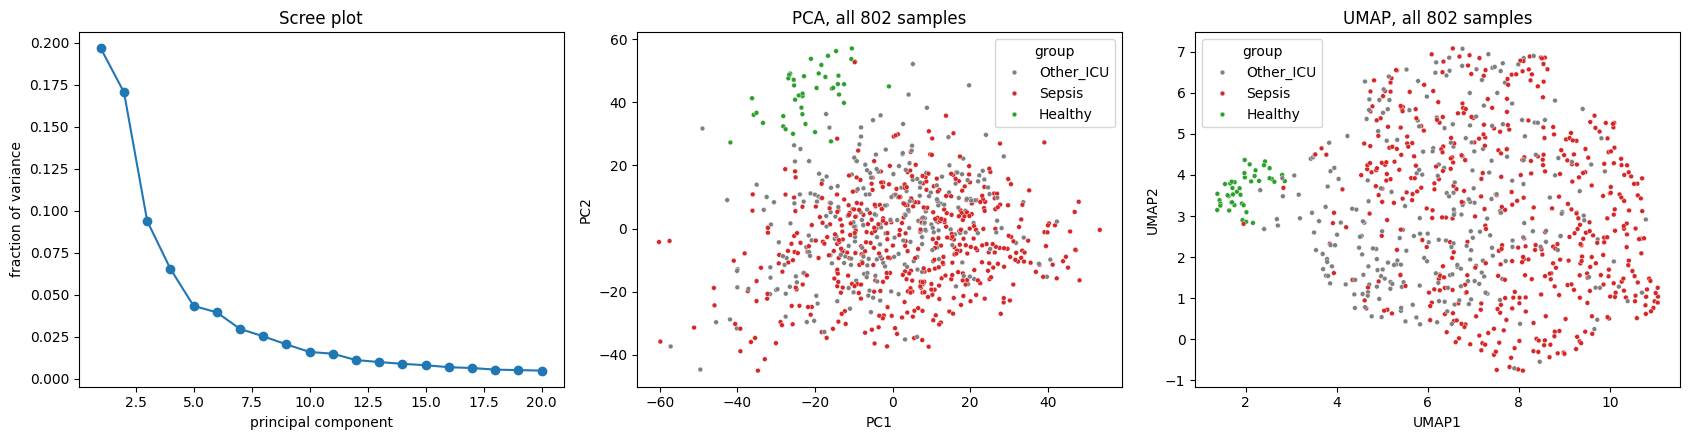

In [6]:
top_all = genes.var(axis=1).sort_values(ascending=False).index[:2000]   # 2,000 most variable genes
Xz_all = StandardScaler().fit_transform(genes.loc[top_all].T)          # z-score each gene
pca_all = PCA(n_components=20, random_state=SEED)
pcs_all = pca_all.fit_transform(Xz_all)
print("variance explained PC1-5:", pca_all.explained_variance_ratio_[:5].round(3),
      "| PC1+PC2:", pca_all.explained_variance_ratio_[:2].sum().round(3))

emb = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=42).fit_transform(pcs_all)
view = pd.DataFrame({"PC1": pcs_all[:, 0], "PC2": pcs_all[:, 1], "UMAP1": emb[:, 0], "UMAP2": emb[:, 1],
                     "group": samples.group.values}, index=samples.index)

pal = {"Healthy": "tab:green", "Other_ICU": "tab:grey", "Sepsis": "tab:red"}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(range(1, 21), pca_all.explained_variance_ratio_, "o-")
ax[0].set_title("Scree plot"); ax[0].set_xlabel("principal component"); ax[0].set_ylabel("fraction of variance")
sns.scatterplot(data=view, x="PC1", y="PC2", hue="group", s=12, palette=pal, ax=ax[1]).set_title("PCA, all 802 samples")
sns.scatterplot(data=view, x="UMAP1", y="UMAP2", hue="group", s=12, palette=pal, ax=ax[2]).set_title("UMAP, all 802 samples")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_pca_umap_all.png"), dpi=150); plt.show()

### Structure of the 479 sepsis patients

clustering input: (479, 10) | variance explained by 10 PCs: 0.69


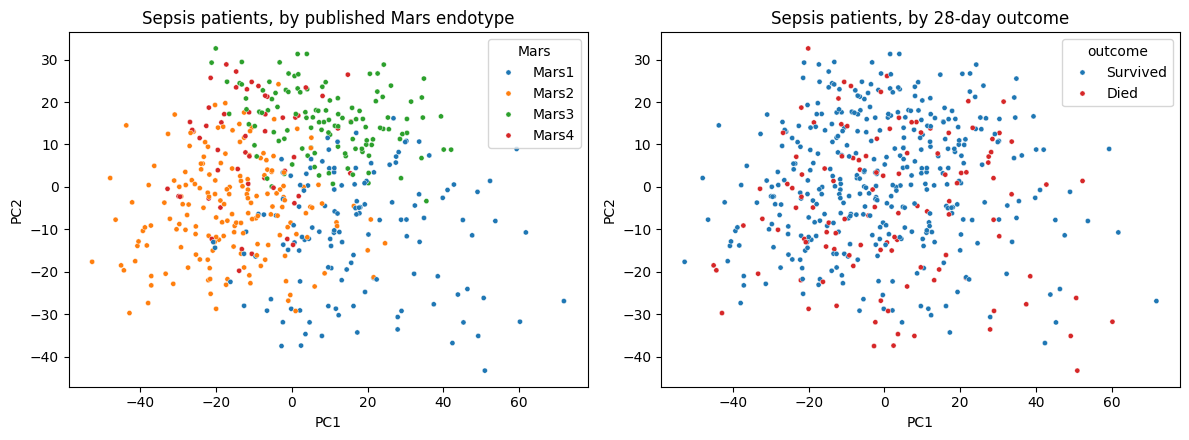

In [7]:
E_sep = genes[sep.index]
top_sep = E_sep.var(axis=1).sort_values(ascending=False).index[:2000]
Xz_sep = StandardScaler().fit_transform(E_sep.loc[top_sep].T)
pca_sep = PCA(n_components=10, random_state=SEED)
P = pca_sep.fit_transform(Xz_sep)                      # 10 PCs = clustering input
print("clustering input:", P.shape, "| variance explained by 10 PCs:", pca_sep.explained_variance_ratio_.sum().round(3))

view_s = pd.DataFrame({"PC1": P[:, 0], "PC2": P[:, 1], "Mars": sep.endotype_class.values,
                       "outcome": sep.outcome.values}, index=sep.index)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=view_s, x="PC1", y="PC2", hue="Mars", s=14, ax=ax[0],
                hue_order=["Mars1", "Mars2", "Mars3", "Mars4"]).set_title("Sepsis patients, by published Mars endotype")
sns.scatterplot(data=view_s, x="PC1", y="PC2", hue="outcome", s=14, ax=ax[1],
                palette={"Survived": "tab:blue", "Died": "tab:red"}).set_title("Sepsis patients, by 28-day outcome")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_pca_sepsis.png"), dpi=150); plt.show()

### Is there a natural number of clusters? (elbow, silhouette)


      inertia  silhouette
k                        
2  520984.026       0.190
3  462761.646       0.148
4  418008.753       0.147
5  392254.333       0.149
6  367156.062       0.145
7  348980.808       0.139
8  331957.425       0.137


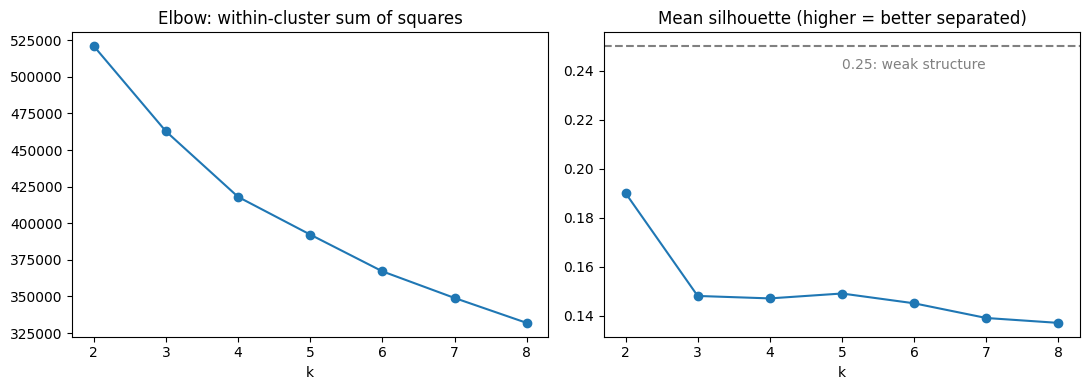

In [8]:
rows = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(P)
    rows.append({"k": k, "inertia": km_k.inertia_, "silhouette": silhouette_score(P, km_k.labels_)})
kres = pd.DataFrame(rows).set_index("k").round(3)
print(kres.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(kres.index, kres.inertia, "o-"); ax[0].set_title("Elbow: within-cluster sum of squares"); ax[0].set_xlabel("k")
ax[1].plot(kres.index, kres.silhouette, "o-"); ax[1].set_title("Mean silhouette (higher = better separated)"); ax[1].set_xlabel("k")
ax[1].axhline(0.25, ls="--", c="grey"); ax[1].text(5, 0.245, "0.25: weak structure", va="top", color="grey")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_choose_k.png"), dpi=150); plt.show()

### k-means with k = 4, compared with the Mars endotypes

Clusters are numbered by their share of Mars1 patients; the Mars labels are used only for numbering, not for forming the clusters.

cluster
C1     98
C2    137
C3    115
C4    129

Contingency table, k-means cluster x Mars endotype:
endotype_class  Mars1  Mars2  Mars3  Mars4
cluster                                   
C1                 92      0      5      1
C2                 21    105      0     11
C3                 11     36     66      2
C4                  8     35     47     39

C1 is 94% Mars1
Rand index vs Mars = 0.731 (with shuffled Mars labels: 0.608)


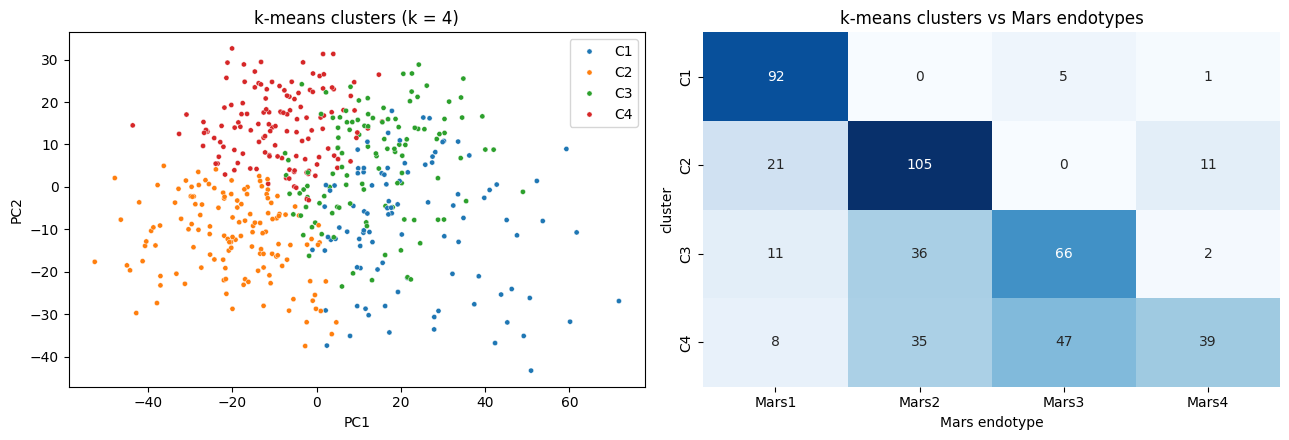

In [9]:
km = KMeans(n_clusters=4, n_init=50, random_state=SEED).fit(P)
raw = pd.Series(km.labels_, index=sep.index)
mars1_share = (sep.endotype_class == "Mars1").groupby(raw).mean().sort_values(ascending=False)
sep["cluster"] = raw.map({lab: f"C{i+1}" for i, lab in enumerate(mars1_share.index)})
CL = ["C1", "C2", "C3", "C4"]
print(sep.cluster.value_counts().sort_index().to_string())

ct_mars = pd.crosstab(sep.cluster, sep.endotype_class)
print("\nContingency table, k-means cluster x Mars endotype:")
print(ct_mars.to_string())
print(f"\nC1 is {100*ct_mars.loc['C1','Mars1']/ct_mars.loc['C1'].sum():.0f}% Mars1")

ri = rand_score(sep.cluster, sep.endotype_class)
rng = np.random.default_rng(SEED)
ri_chance = np.mean([rand_score(sep.cluster, rng.permutation(sep.endotype_class.values)) for _ in range(200)])
print(f"Rand index vs Mars = {ri:.3f} (with shuffled Mars labels: {ri_chance:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=sep.cluster.values, hue_order=CL, s=14, ax=ax[0])
ax[0].set_title("k-means clusters (k = 4)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
sns.heatmap(ct_mars, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1])
ax[1].set_title("k-means clusters vs Mars endotypes"); ax[1].set_xlabel("Mars endotype"); ax[1].set_ylabel("cluster")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_kmeans_vs_mars.png"), dpi=150); plt.show()

### Second method: hierarchical clustering, shown as a heatmap



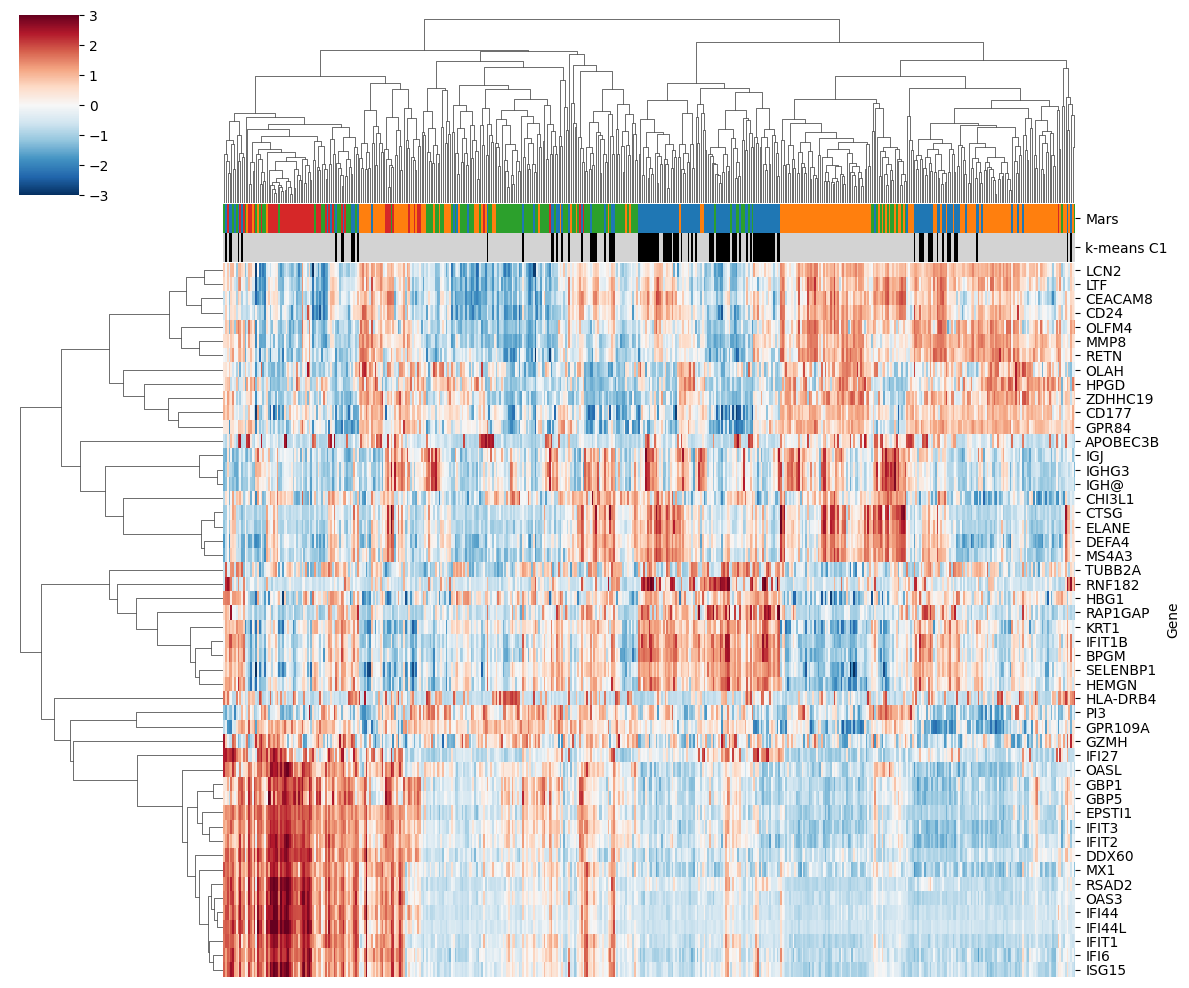

Hierarchical group x Mars endotype:
endotype_class  Mars1  Mars2  Mars3  Mars4
hier                                      
H1                 14     29     20     48
H2                 17     24     77      4
H3                 69      3      8      0
H4                 32    120     13      1

Mars1-richest hierarchical group H3: 69 of 80 patients are Mars1
Hierarchical group x k-means cluster:
cluster  C1  C2  C3  C4
hier                   
H1       11  29  12  59
H2       16   4  54  48
H3       55  10   9   6
H4       16  94  40  16


In [10]:
SEX_GENES = ["XIST", "RPS4Y1", "EIF1AY", "DDX3Y", "KDM5D", "UTY", "USP9Y", "ZFY"]
v = E_sep.var(axis=1).sort_values(ascending=False)
top50 = [g for g in v.index if g not in SEX_GENES][:50]

mars_col = sep.endotype_class.map({"Mars1": "tab:blue", "Mars2": "tab:orange", "Mars3": "tab:green", "Mars4": "tab:red"})
km_col = sep.cluster.map({"C1": "black", "C2": "lightgrey", "C3": "lightgrey", "C4": "lightgrey"})
cg = sns.clustermap(E_sep.loc[top50], z_score=0, cmap="RdBu_r", vmin=-3, vmax=3,
                    col_colors=pd.DataFrame({"Mars": mars_col, "k-means C1": km_col}),
                    xticklabels=False, yticklabels=True, figsize=(12, 10),
                    method="average", metric="correlation")
cg.savefig(os.path.join(FIG, "04_heatmap_hierarchical.png"), dpi=120); plt.show()

sep["hier"] = pd.Series(fcluster(cg.dendrogram_col.linkage, 4, criterion="maxclust"), index=sep.index).map(lambda x: f"H{x}")
ct_h = pd.crosstab(sep.hier, sep.endotype_class)
print("Hierarchical group x Mars endotype:"); print(ct_h.to_string())
h1 = ct_h["Mars1"].div(ct_h.sum(1)).idxmax()           # Mars1-richest hierarchical group
print(f"\nMars1-richest hierarchical group {h1}: {ct_h.loc[h1,'Mars1']} of {ct_h.loc[h1].sum()} patients are Mars1")
print("Hierarchical group x k-means cluster:"); print(pd.crosstab(sep.hier, sep.cluster).to_string())

### Technical check: are the clusters driven by array batch or sex?

In [11]:
run_date = sep.title.str.extract(r"\[(\d\d_\d\d_\d{4})")[0]
r2 = [smf.ols("pc ~ C(run)", data=pd.DataFrame({"pc": P[:, i], "run": run_date.values})).fit().rsquared for i in range(5)]
print(f"{run_date.nunique()} array run dates explain at most {100*max(r2):.1f}% of the variance of PC1-5")

top_ns = [g for g in top_sep if g not in SEX_GENES]
P_ns = PCA(n_components=10, random_state=SEED).fit_transform(StandardScaler().fit_transform(E_sep.loc[top_ns].T))
lab_ns = KMeans(n_clusters=4, n_init=50, random_state=SEED).fit_predict(P_ns)
print(f"Rand index between clusters with and without sex-chromosome genes: {rand_score(sep.cluster, lab_ns):.3f}")
sep[["cluster", "hier"]].to_csv(os.path.join(RES, "clusters.csv"))

14 array run dates explain at most 2.5% of the variance of PC1-5
Rand index between clusters with and without sex-chromosome genes: 0.996


## Q2: Do these subgroups differ in 28 day mortality, independent of age, sex and cohort?

### Mortality by cluster (chi-squared test)

**H0:** 28 day mortality is the same in all four clusters. **H1:** at least one cluster differs.

28-day mortality by cluster: {'C1': 32.7, 'C2': 26.3, 'C3': 20.0, 'C4': 17.8}
chi2 = 8.15, df = 3, p = 0.0430 (smallest expected count 23.3)


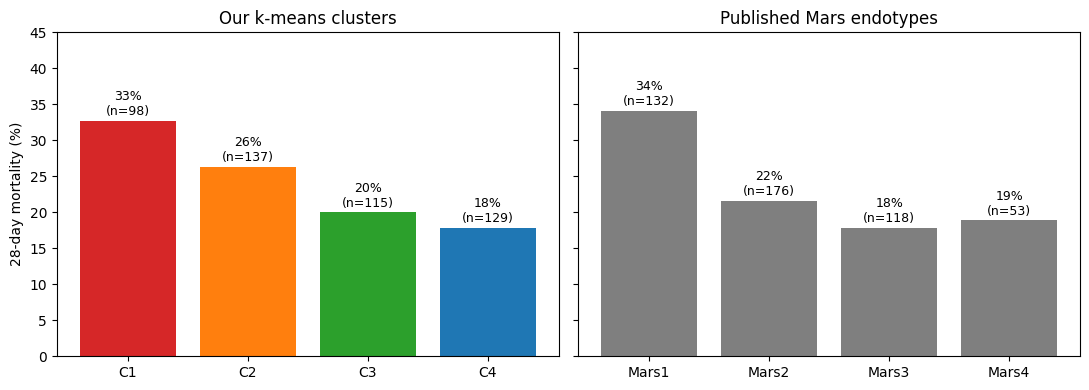

In [12]:
ct_death = pd.crosstab(sep.cluster, sep.died)
chi2, p_chi, dof, expected = stats.chi2_contingency(ct_death)
rate = sep.groupby("cluster").died.mean()
print("28-day mortality by cluster:", (100 * rate).round(1).to_dict())
print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p_chi:.4f} (smallest expected count {expected.min():.1f})")

mrate = sep.groupby("endotype_class").died.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, r, n, title, colors in [
        (ax[0], rate, sep.cluster.value_counts().sort_index(), "Our k-means clusters", ["tab:red", "tab:orange", "tab:green", "tab:blue"]),
        (ax[1], mrate, sep.endotype_class.value_counts().sort_index(), "Published Mars endotypes", "tab:grey")]:
    a.bar(r.index, 100 * r.values, color=colors)
    for i, (x, m) in enumerate(zip(r.values, n.values)):
        a.text(i, 100 * x + 0.8, f"{100*x:.0f}%\n(n={m})", ha="center", fontsize=9)
    a.set_title(title); a.set_ylim(0, 45)
ax[0].set_ylabel("28-day mortality (%)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "05_mortality_by_cluster.png"), dpi=150); plt.show()

### Is the C1 effect explained by age, sex or cohort? (logistic regression)



In [13]:
sep["C1"] = (sep.cluster == "C1").astype(int)
sep["male"] = (sep.gender == "male").astype(int)
sep["validation_cohort"] = (sep.endotype_cohort == "validation").astype(int)

crude = smf.logit("died ~ C1", data=sep).fit(disp=0)
model = smf.logit("died ~ C1 + age + male + validation_cohort", data=sep).fit(disp=0)

ci = np.exp(model.conf_int())
or_table = pd.DataFrame({"odds ratio": np.exp(model.params), "95% CI low": ci[0], "95% CI high": ci[1],
                         "p": model.pvalues}).drop("Intercept").round(3)
print(or_table.to_string())
print(f"\nC1 odds ratio: crude {np.exp(crude.params['C1']):.2f} -> adjusted {or_table.loc['C1','odds ratio']:.2f} "
      f"(95% CI {or_table.loc['C1','95% CI low']:.2f}-{or_table.loc['C1','95% CI high']:.2f}), n = {int(model.nobs)}")
or_table.to_csv(os.path.join(RES, "logistic_regression.csv"))

                   odds ratio  95% CI low  95% CI high      p
C1                      1.761       1.073        2.892  0.025
age                     1.024       1.008        1.041  0.003
male                    1.153       0.745        1.783  0.523
validation_cohort       0.702       0.453        1.086  0.112

C1 odds ratio: crude 1.77 -> adjusted 1.76 (95% CI 1.07-2.89), n = 479


## Q3: Which genes and biological pathways distinguish patients who died from those who survived?

### Differential expression (Welch t-test with Benjamini-Hochberg FDR)


**H0 (each gene):** mean expression is the same in patients who died and those who survived. **H1:** it differs.

genes tested: 8201
FDR < 0.05: 680 genes (116 higher, 564 lower in non-survivors)
largest |log2FC| among them: 0.97
            log2FC        p      FDR
Gene                                
TNFSF12     -0.228 2.24e-07 0.000873
TRIM27      -0.353 3.76e-07 0.000873
TNFRSF8     -0.253 4.12e-07 0.000873
CX3CR1      -0.813 4.26e-07 0.000873
TUBG2        0.467 6.02e-07 0.000987
AMICA1      -0.318 1.85e-06  0.00253
NCRNA00188   0.344  3.2e-06  0.00314
ZNF862      -0.236 3.26e-06  0.00314
CALHM2       -0.33 3.81e-06  0.00314
INTS3       -0.134 3.92e-06  0.00314


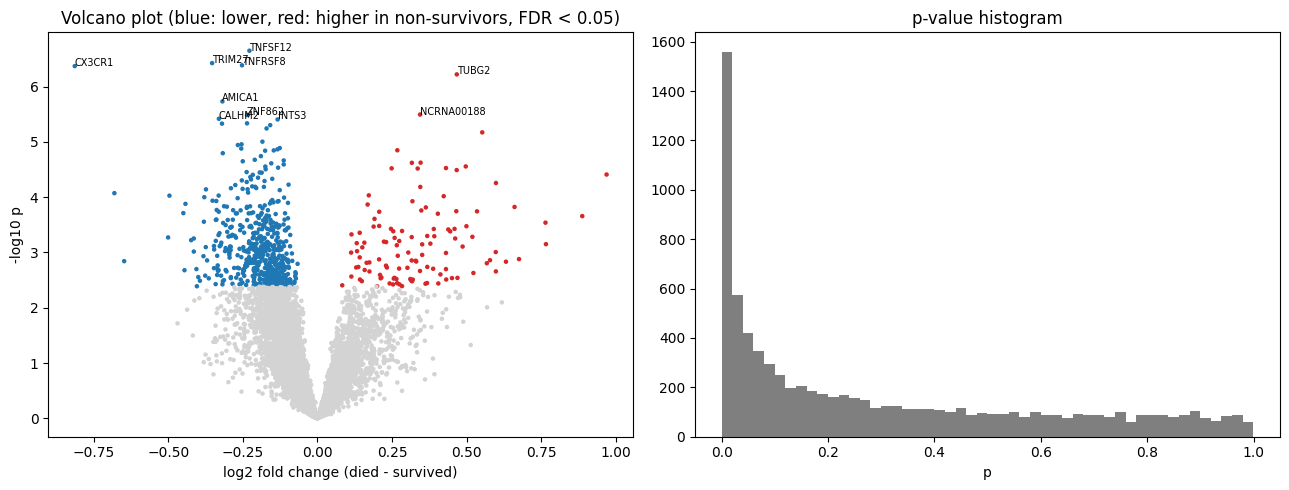

In [14]:
E = E_sep[E_sep.mean(axis=1) >= 3]
print("genes tested:", E.shape[0])

def de_test(E, in_group):
    a, b = E.loc[:, in_group], E.loc[:, ~in_group]
    t, p = stats.ttest_ind(a, b, axis=1, equal_var=False)
    res = pd.DataFrame({"log2FC": a.mean(1) - b.mean(1), "t": t, "p": p}, index=E.index)
    res["FDR"] = multipletests(res.p, method="fdr_bh")[1]
    return res.sort_values("p")

died = (sep.died == 1).values
de = de_test(E, died)
sig = de[de.FDR < 0.05]
print(f"FDR < 0.05: {len(sig)} genes ({(sig.log2FC > 0).sum()} higher, {(sig.log2FC < 0).sum()} lower in non-survivors)")
print(f"largest |log2FC| among them: {sig.log2FC.abs().max():.2f}")
print(de.head(10)[["log2FC", "p", "FDR"]].to_string(float_format="%.3g"))
de.to_csv(os.path.join(RES, "DE_died_vs_survived.csv"))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
c = np.where((de.FDR < 0.05) & (de.log2FC > 0), "tab:red", np.where((de.FDR < 0.05) & (de.log2FC < 0), "tab:blue", "lightgrey"))
ax[0].scatter(de.log2FC, -np.log10(de.p), c=c, s=5)
for g in de.index[:10]:
    ax[0].annotate(g, (de.log2FC[g], -np.log10(de.p[g])), fontsize=7)
ax[0].set_xlabel("log2 fold change (died - survived)"); ax[0].set_ylabel("-log10 p")
ax[0].set_title("Volcano plot (blue: lower, red: higher in non-survivors, FDR < 0.05)")
ax[1].hist(de.p, bins=50, color="tab:grey"); ax[1].set_title("p-value histogram"); ax[1].set_xlabel("p")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "06_volcano.png"), dpi=150); plt.show()

### Over-representation analysis (Fisher's exact test)


**H0 (each gene set):** our significant genes are no more common in the set than in the background.

In [15]:
def ora(hits, background, gene_sets, min_size=10):
    hits, background = set(hits), set(background)
    rows = []
    for name, members in gene_sets.items():
        m = members & background
        if len(m) < min_size:
            continue
        a = len(hits & m)                               # significant and in set
        b = len(hits) - a                               # significant, not in set
        c = len(m) - a                                  # in set, not significant
        d = len(background) - len(hits) - c             # neither
        odds, p = stats.fisher_exact([[a, b], [c, d]], alternative="greater")
        rows.append({"gene_set": name, "overlap": a, "set_size": len(m), "odds_ratio": odds, "p": p})
    out = pd.DataFrame(rows)
    out["FDR"] = multipletests(out.p, method="fdr_bh")[1]
    return out.sort_values("p").reset_index(drop=True)

background = E.index
ora_down = ora(sig.index[sig.log2FC < 0], background, hallmark)
ora_up = ora(sig.index[sig.log2FC > 0], background, hallmark)
for name, r in [("LOWER in non-survivors", ora_down), ("HIGHER in non-survivors", ora_up)]:
    print(f"\nGenes {name}: {int((r.FDR < 0.05).sum())} gene sets at FDR < 0.05")
    print(r.head(8).to_string(float_format="%.3g"))
ora_down.to_csv(os.path.join(RES, "ORA_lower_in_died.csv"), index=False)
ora_up.to_csv(os.path.join(RES, "ORA_higher_in_died.csv"), index=False)


Genes LOWER in non-survivors: 2 gene sets at FDR < 0.05
                    gene_set  overlap  set_size  odds_ratio        p      FDR
0  INTERFERON_GAMMA_RESPONSE       28       163         2.9 5.25e-06 0.000257
1  INTERFERON_ALPHA_RESPONSE       14        77        3.06 0.000667   0.0163
2        ALLOGRAFT_REJECTION       17       129        2.09  0.00701    0.114
3            NOTCH_SIGNALING        4        17        4.19   0.0257    0.314
4                 COMPLEMENT       12       126        1.43    0.157        1
5      INFLAMMATORY_RESPONSE       11       118         1.4    0.187        1
6    PI3K_AKT_MTOR_SIGNALING        7        71        1.49    0.214        1
7                  APOPTOSIS        9       111         1.2    0.354        1

Genes HIGHER in non-survivors: 3 gene sets at FDR < 0.05
                  gene_set  overlap  set_size  odds_ratio        p      FDR
0          HEME_METABOLISM       27       160        18.1 3.22e-22 1.58e-20
1                  HYPOXIA     

### Gene set enrichment analysis (GSEA, pre-ranked)



20 gene sets at FDR < 0.25 (9 lower, 11 higher in non-survivors)
                                 Term   NES  NOM p-val  FDR q-val
0           INTERFERON_ALPHA_RESPONSE    -2          0    0.00056
1           INTERFERON_GAMMA_RESPONSE -1.93          0    0.00028
2                 ALLOGRAFT_REJECTION -1.85          0    0.00112
3               INFLAMMATORY_RESPONSE -1.64    0.00103     0.0132
4                          COMPLEMENT -1.54     0.0031     0.0365
5             IL6_JAK_STAT3_SIGNALING -1.49      0.012     0.0505
6                     NOTCH_SIGNALING -1.33      0.118      0.213
7          WNT_BETA_CATENIN_SIGNALING -1.32       0.13      0.207
8                      APICAL_SURFACE -1.29      0.146      0.239
37                    SPERMATOGENESIS  1.24      0.115      0.232
38              XENOBIOTIC_METABOLISM  1.28          0      0.199
39             ESTROGEN_RESPONSE_LATE  1.36          0      0.127
40  EPITHELIAL_MESENCHYMAL_TRANSITION   1.4     0.0149      0.101
41         

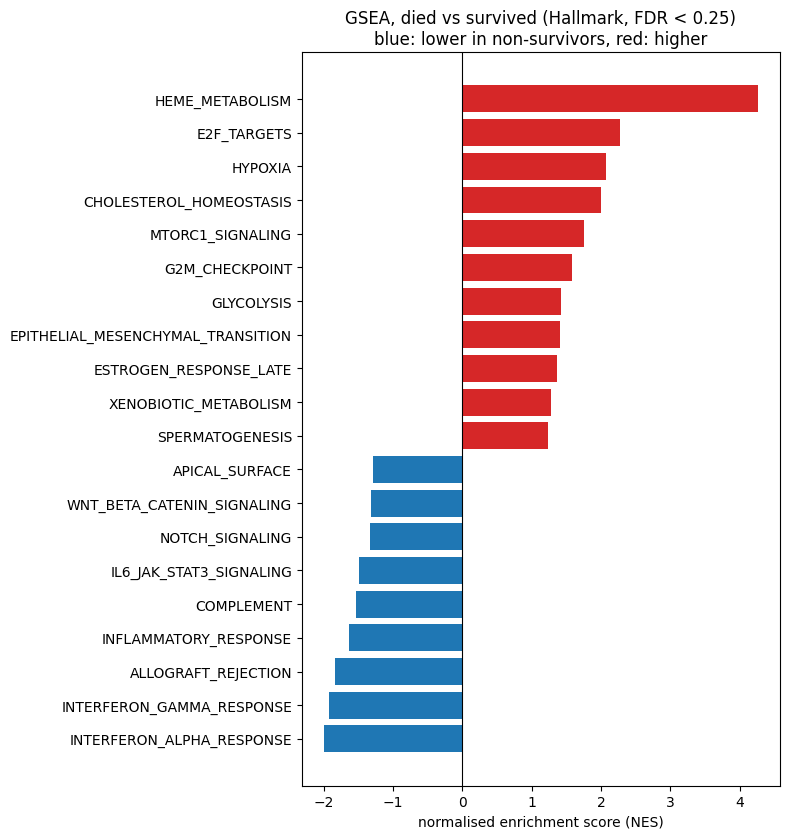

In [16]:
rnk = de.t.sort_values(ascending=False)
pre = gseapy.prerank(rnk=rnk, gene_sets=GMT, permutation_num=1000, min_size=15, max_size=500,
                     seed=SEED, threads=2, outdir=None, verbose=False)
gsea = pre.res2d.copy()
gsea["Term"] = gsea["Term"].str.replace("HALLMARK_", "")
gsea[["NES", "NOM p-val", "FDR q-val"]] = gsea[["NES", "NOM p-val", "FDR q-val"]].astype(float)
gsea = gsea.sort_values("NES")[["Term", "NES", "NOM p-val", "FDR q-val"]].reset_index(drop=True)
gsea.to_csv(os.path.join(RES, "GSEA_died_vs_survived.csv"), index=False)

sig_gsea = gsea[gsea["FDR q-val"] < 0.25]
print(f"{len(sig_gsea)} gene sets at FDR < 0.25 ({(sig_gsea.NES < 0).sum()} lower, {(sig_gsea.NES > 0).sum()} higher in non-survivors)")
print(sig_gsea.to_string(float_format="%.3g"))

if len(sig_gsea):
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(sig_gsea) + 1.5))
    ax.barh(sig_gsea.Term, sig_gsea.NES, color=np.where(sig_gsea.NES < 0, "tab:blue", "tab:red"))
    ax.axvline(0, c="k", lw=0.8)
    ax.set_xlabel("normalised enrichment score (NES)")
    ax.set_title("GSEA, died vs survived (Hallmark, FDR < 0.25)\nblue: lower in non-survivors, red: higher")
    plt.tight_layout(); plt.savefig(os.path.join(FIG, "06_gsea.png"), dpi=150); plt.show()

### Biology of the high-risk cluster C1 (marker genes + over-representation)



C1 markers: 252 higher, 34 lower than in other clusters
top higher in C1: ['GLRX5', 'EPB42', 'CA1', 'SELENBP1', 'BNIP3L', 'AHSP', 'GMPR', 'C20orf108', 'HBD', 'SLC4A1']
top lower in C1:  ['DLGAP4', 'KIAA0754', 'DHX16', 'SIGLEC7', 'PPM1M', 'GALNT14', 'PGD', 'DICER1', 'LOC440459', 'EMILIN2']

Markers HIGHER in C1: 5 gene sets at FDR < 0.05
                  gene_set  overlap  set_size  odds_ratio        p      FDR
0          HEME_METABOLISM       75       160        39.2 2.49e-73 1.22e-71
1  ESTROGEN_RESPONSE_EARLY        9        80        4.11 0.000731   0.0179
2    XENOBIOTIC_METABOLISM       10       106        3.38   0.0015   0.0245
3                  HYPOXIA       10       115        3.09  0.00276   0.0338
4   ESTROGEN_RESPONSE_LATE        8        84         3.4  0.00413   0.0405
5      IL2_STAT5_SIGNALING        9       124        2.52    0.014    0.114

Markers LOWER in C1: 0 gene sets at FDR < 0.05
                  gene_set  overlap  set_size  odds_ratio     p  FDR
0     BILE_A

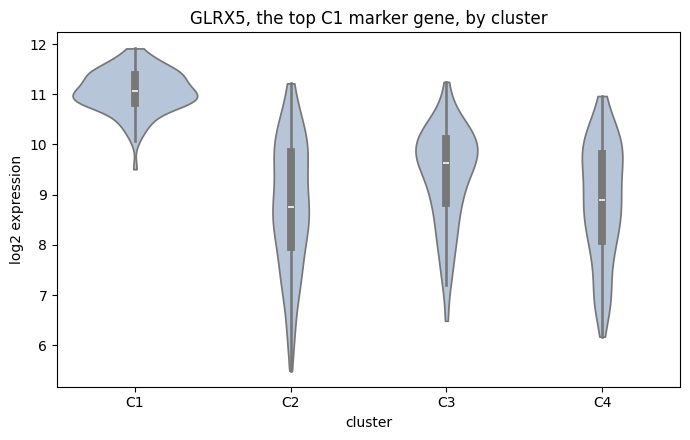

In [17]:
c1 = de_test(E, (sep.cluster == "C1").values)
c1_up = c1.index[(c1.FDR < 0.05) & (c1.log2FC > 1)]
c1_down = c1.index[(c1.FDR < 0.05) & (c1.log2FC < -1)]
print(f"C1 markers: {len(c1_up)} higher, {len(c1_down)} lower than in other clusters")
print("top higher in C1:", c1.loc[c1_up].sort_values("p").index[:10].tolist())
print("top lower in C1: ", c1.loc[c1_down].sort_values("p").index[:10].tolist())
c1.to_csv(os.path.join(RES, "DE_C1_vs_rest.csv"))

ora_c1_up = ora(c1_up, background, hallmark)
ora_c1_down = ora(c1_down, background, hallmark)
for name, r in [("HIGHER in C1", ora_c1_up), ("LOWER in C1", ora_c1_down)]:
    print(f"\nMarkers {name}: {int((r.FDR < 0.05).sum())} gene sets at FDR < 0.05")
    print(r.head(6).to_string(float_format="%.3g"))
ora_c1_up.to_csv(os.path.join(RES, "ORA_C1_higher.csv"), index=False)
ora_c1_down.to_csv(os.path.join(RES, "ORA_C1_lower.csv"), index=False)

top_marker = c1.loc[c1_up].sort_values("p").index[0]
d = pd.DataFrame({"expression": E.loc[top_marker].values, "cluster": sep.cluster.values})
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.violinplot(data=d, x="cluster", y="expression", order=CL, inner="box", cut=0, color="lightsteelblue", ax=ax)
ax.set_title(f"{top_marker}, the top C1 marker gene, by cluster"); ax.set_ylabel("log2 expression")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "06_violin_top_C1_marker.png"), dpi=150); plt.show()

## Q4: Can blood gene expression predict 28 day mortality better than age alone?


                                AUROC mean  AUROC SD
Age only (logistic regression)       0.585     0.057
Lasso logistic regression            0.691     0.063
Random forest                        0.659     0.083
SVM (RBF kernel)                     0.673     0.062


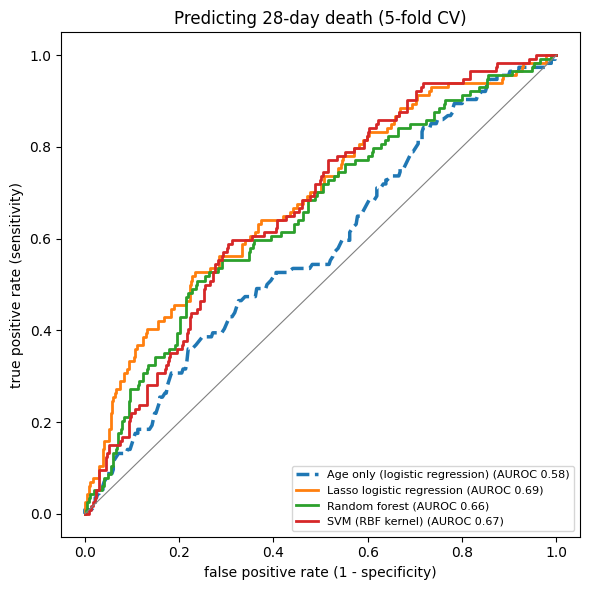

In [18]:
X_genes = E.T.values
X_age = sep[["age"]].values
y = sep.died.values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def gene_model(clf):
    return make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200), clf)

models = {
    "Age only (logistic regression)": (make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced")), X_age),
    "Lasso logistic regression": (gene_model(LogisticRegression(penalty="l1", solver="liblinear", C=0.05,
                                                                class_weight="balanced")), X_genes),
    "Random forest": (gene_model(RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight="balanced",
                                                        random_state=SEED, n_jobs=-1)), X_genes),
    "SVM (RBF kernel)": (gene_model(SVC(kernel="rbf", class_weight="balanced", random_state=SEED)), X_genes),
}

scores, fold_auc = {}, {}
for name, (model, X) in models.items():
    s = np.zeros(len(y)); aucs = []
    for train, test in cv.split(X, y):
        model.fit(X[train], y[train])
        s[test] = model.decision_function(X[test]) if hasattr(model, "decision_function") else model.predict_proba(X[test])[:, 1]
        aucs.append(roc_auc_score(y[test], s[test]))
    scores[name], fold_auc[name] = s, aucs

auc_table = pd.DataFrame({"AUROC mean": [np.mean(v) for v in fold_auc.values()],
                          "AUROC SD": [np.std(v) for v in fold_auc.values()]}, index=list(fold_auc)).round(3)
print(auc_table.to_string())
auc_table.to_csv(os.path.join(RES, "classifier_auroc.csv"))

fig, ax = plt.subplots(figsize=(6, 6))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, lw=2 if "Age" not in name else 2.5, ls="--" if "Age" in name else "-",
            label=f"{name} (AUROC {auc_table.loc[name, 'AUROC mean']:.2f})")
ax.plot([0, 1], [0, 1], c="grey", lw=0.8)
ax.set_xlabel("false positive rate (1 - specificity)"); ax.set_ylabel("true positive rate (sensitivity)")
ax.set_title("Predicting 28-day death (5-fold CV)"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "07_roc.png"), dpi=150); plt.show()

### Which genes does the lasso model use?

In [19]:
lasso = models["Lasso logistic regression"][0].fit(X_genes, y)
kept = E.index[lasso.named_steps["selectkbest"].get_support()]
coef = pd.Series(lasso.named_steps["logisticregression"].coef_[0], index=kept)
coef = coef[coef != 0].sort_values()
print(f"lasso keeps {len(coef)} of 200 selected genes (fitted on all 479 patients)")
print("lower expression -> higher risk:", coef.index[coef < 0].tolist())
print("higher expression -> higher risk:", coef.index[coef > 0].tolist())
coef.to_csv(os.path.join(RES, "lasso_genes.csv"))

lasso keeps 19 of 200 selected genes (fitted on all 479 patients)
lower expression -> higher risk: ['ING4', 'TRIM27', 'TNFSF12', 'DENND2D', 'TNFRSF8', 'FAM38A', 'POC5', 'CX3CR1', 'TCHP', 'CD84', 'UBAC2', 'ZNF862']
higher expression -> higher risk: ['TSC22D3', 'DEFA4', 'HSBP1L1', 'NCRNA00188', 'DDIT4', 'DAAM2', 'TUBG2']


## Comparison with Scicluna et al. (2017)

In [20]:
print(f"Mars1 28-day mortality in our data: {100*mrate['Mars1']:.1f}% (Scicluna discovery cohort: 39%)")
print(f"Our C1 28-day mortality: {100*rate['C1']:.1f}%; C1 is {100*ct_mars.loc['C1','Mars1']/ct_mars.loc['C1'].sum():.0f}% Mars1")
print(f"BPGM, C1 vs rest: log2FC {c1.loc['BPGM','log2FC']:+.2f}, FDR {c1.loc['BPGM','FDR']:.1e}")
print(f"TAP2, C1 vs rest: log2FC {c1.loc['TAP2','log2FC']:+.2f}, FDR {c1.loc['TAP2','FDR']:.1e}")
print("C1 higher, top gene sets:", ora_c1_up[ora_c1_up.FDR < 0.05].gene_set.head(5).tolist())
print("C1 lower, top gene sets: ", ora_c1_down[ora_c1_down.FDR < 0.05].gene_set.head(5).tolist())
print("Non-survivors lower (GSEA FDR<0.25):", gsea[(gsea['FDR q-val'] < 0.25) & (gsea.NES < 0)].Term.head(6).tolist())

Mars1 28-day mortality in our data: 34.1% (Scicluna discovery cohort: 39%)
Our C1 28-day mortality: 32.7%; C1 is 94% Mars1
BPGM, C1 vs rest: log2FC +3.16, FDR 9.8e-68
TAP2, C1 vs rest: log2FC -0.46, FDR 5.6e-05
C1 higher, top gene sets: ['HEME_METABOLISM', 'ESTROGEN_RESPONSE_EARLY', 'XENOBIOTIC_METABOLISM', 'HYPOXIA', 'ESTROGEN_RESPONSE_LATE']
C1 lower, top gene sets:  []
Non-survivors lower (GSEA FDR<0.25): ['INTERFERON_ALPHA_RESPONSE', 'INTERFERON_GAMMA_RESPONSE', 'ALLOGRAFT_REJECTION', 'INFLAMMATORY_RESPONSE', 'COMPLEMENT', 'IL6_JAK_STAT3_SIGNALING']


## Summary of key results

In [21]:
summary = {
    "Samples / sepsis / died": f"{len(samples)} / {len(sep)} / {sep.died.sum()} ({100*sep.died.mean():.1f}%)",
    "Q1 PC1+PC2 variance, all samples": f"{100*pca_all.explained_variance_ratio_[:2].sum():.0f}%",
    "Q1 best silhouette (k)": f"{kres.silhouette.max():.2f} (k = {kres.silhouette.idxmax()})",
    "Q1 cluster sizes C1-C4": sep.cluster.value_counts().sort_index().tolist(),
    "Q1 C1 share Mars1": f"{100*ct_mars.loc['C1','Mars1']/ct_mars.loc['C1'].sum():.0f}%",
    "Q1 Rand index vs Mars (chance)": f"{ri:.2f} ({ri_chance:.2f})",
    "Q1 hierarchical Mars1-rich group": f"{ct_h.loc[h1,'Mars1']} of {ct_h.loc[h1].sum()} are Mars1",
    "Q2 mortality C1-C4": (100 * rate).round(1).tolist(),
    "Q2 chi-squared p": round(p_chi, 4),
    "Q2 C1 OR crude -> adjusted (95% CI)": f"{np.exp(crude.params['C1']):.2f} -> {or_table.loc['C1','odds ratio']:.2f} "
                                             f"({or_table.loc['C1','95% CI low']:.2f}-{or_table.loc['C1','95% CI high']:.2f}), p = {or_table.loc['C1','p']:.3f}",
    "Q3 genes FDR<0.05 (lower/higher in died)": f"{len(sig)} ({(sig.log2FC<0).sum()}/{(sig.log2FC>0).sum()})",
    "Q3 ORA sets FDR<0.05 (lower/higher)": f"{(ora_down.FDR<0.05).sum()}/{(ora_up.FDR<0.05).sum()}",
    "Q3 GSEA sets FDR<0.25": len(sig_gsea),
    "Q3 C1 markers (higher/lower)": f"{len(c1_up)}/{len(c1_down)}",
    "Q4 AUROC": "; ".join(f"{k}: {r['AUROC mean']:.2f} ± {r['AUROC SD']:.2f}" for k, r in auc_table.iterrows()),
}
for k, v in summary.items():
    print(f"{k:42s} {v}")
pd.Series(summary).astype(str).to_csv(os.path.join(RES, "summary.csv"))

Samples / sepsis / died                    802 / 479 / 114 (23.8%)
Q1 PC1+PC2 variance, all samples           37%
Q1 best silhouette (k)                     0.19 (k = 2)
Q1 cluster sizes C1-C4                     [98, 137, 115, 129]
Q1 C1 share Mars1                          94%
Q1 Rand index vs Mars (chance)             0.73 (0.61)
Q1 hierarchical Mars1-rich group           69 of 80 are Mars1
Q2 mortality C1-C4                         [32.7, 26.3, 20.0, 17.8]
Q2 chi-squared p                           0.043
Q2 C1 OR crude -> adjusted (95% CI)        1.77 -> 1.76 (1.07-2.89), p = 0.025
Q3 genes FDR<0.05 (lower/higher in died)   680 (564/116)
Q3 ORA sets FDR<0.05 (lower/higher)        2/3
Q3 GSEA sets FDR<0.25                      20
Q3 C1 markers (higher/lower)               252/34
Q4 AUROC                                   Age only (logistic regression): 0.58 ± 0.06; Lasso logistic regression: 0.69 ± 0.06; Random forest: 0.66 ± 0.08; SVM (RBF kernel): 0.67 ± 0.06


## Annex (Supplementary Material): extra checks for Q1 and Q3




### A1. Calinski-Harabasz score for k = 2-8 (Q1)



      inertia  silhouette  calinski_harabasz
k                                           
2  520984.026       0.190            128.374
3  462761.646       0.148            102.055
4  418008.753       0.147             92.114
5  392254.333       0.149             81.247
6  367156.062       0.145             75.761
7  348980.808       0.139             70.379
8  331957.425       0.137             66.734


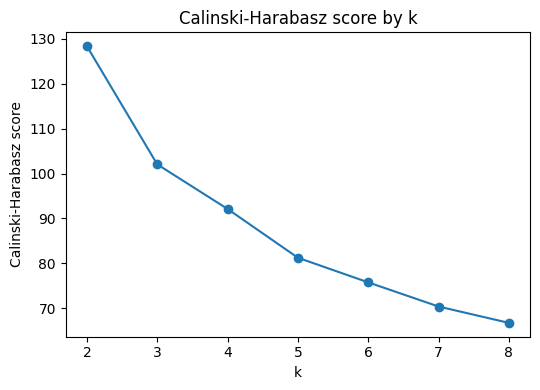

In [22]:
from sklearn.metrics import calinski_harabasz_score
kres["calinski_harabasz"] = [calinski_harabasz_score(P, KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(P))
                             for k in kres.index]
kres = kres.round(3)
print(kres.to_string())
kres.to_csv(os.path.join(RES, "annex_A1_cluster_scores.csv"))

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(kres.index, kres.calinski_harabasz, "o-")
ax.set_xlabel("k"); ax.set_ylabel("Calinski-Harabasz score"); ax.set_title("Calinski-Harabasz score by k")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "annex_A1_calinski_harabasz.png"), dpi=150); plt.show()

### A2. DBSCAN, a density-based method (Q1)



eps (percentile of 10-NN distance)  clusters  noise %   cluster sizes
                        20.1 (5th)         4     74.1 [88, 16, 11, 9]
                       20.9 (10th)         4     59.5  [176, 8, 6, 4]
                       22.2 (25th)         1     36.7           [303]
                       23.9 (40th)         1     23.8           [365]
                       24.8 (50th)         1     15.2           [406]
                       26.0 (60th)         1     10.6           [428]
                       28.0 (75th)         1      8.1           [440]
                       32.7 (90th)         1      1.9           [470]
                       35.0 (95th)         1      0.8           [475]


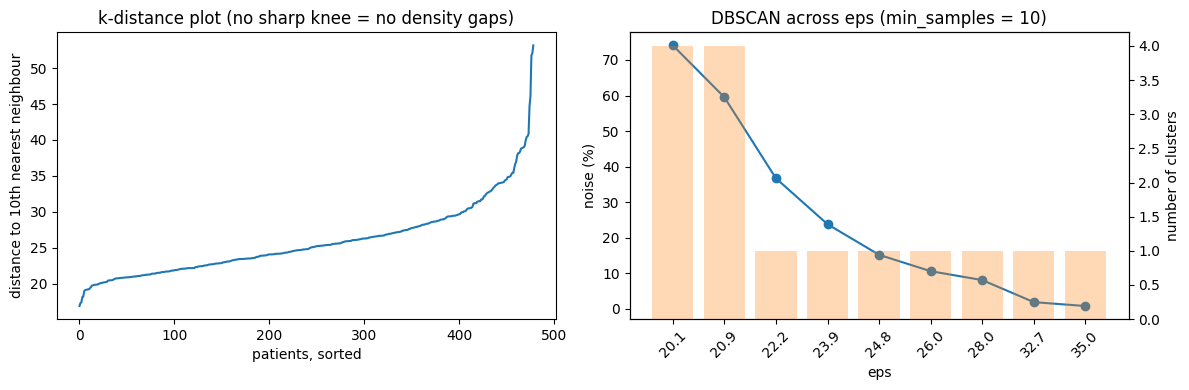

In [23]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

kdist = np.sort(NearestNeighbors(n_neighbors=10).fit(P).kneighbors(P)[0][:, -1])
rows = []
for q in [5, 10, 25, 40, 50, 60, 75, 90, 95]:
    eps = np.percentile(kdist, q)
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(P)
    sizes = sorted(np.bincount(lab[lab >= 0]).tolist(), reverse=True) if (lab >= 0).any() else []
    rows.append({"eps (percentile of 10-NN distance)": f"{eps:.1f} ({q}th)", "clusters": len(sizes),
                 "noise %": round(100 * (lab == -1).mean(), 1), "cluster sizes": sizes})
dbs = pd.DataFrame(rows)
print(dbs.to_string(index=False))
dbs.to_csv(os.path.join(RES, "annex_A2_dbscan.csv"), index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(kdist); ax[0].set_xlabel("patients, sorted"); ax[0].set_ylabel("distance to 10th nearest neighbour")
ax[0].set_title("k-distance plot (no sharp knee = no density gaps)")
ax[1].plot(dbs.index, dbs["noise %"], "o-", label="noise %")
ax2 = ax[1].twinx(); ax2.bar(dbs.index, dbs.clusters, alpha=0.3, color="tab:orange", label="clusters")
ax[1].set_xticks(dbs.index); ax[1].set_xticklabels([r.split(" ")[0] for r in dbs.iloc[:, 0]], rotation=45)
ax[1].set_xlabel("eps"); ax[1].set_ylabel("noise (%)"); ax2.set_ylabel("number of clusters")
ax[1].set_title("DBSCAN across eps (min_samples = 10)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "annex_A2_dbscan.png"), dpi=150); plt.show()

### A3. Does the Q3 gene list depend on the t-test? (Mann-Whitney check)



t-test genes (FDR < 0.05): 680
Mann-Whitney genes (FDR < 0.05): 748
found by both: 590 (87% of the t-test genes)
Spearman correlation of -log10 p across all genes: 0.952
genes with unequal variances (F-test, FDR < 0.05): 189 of 8201


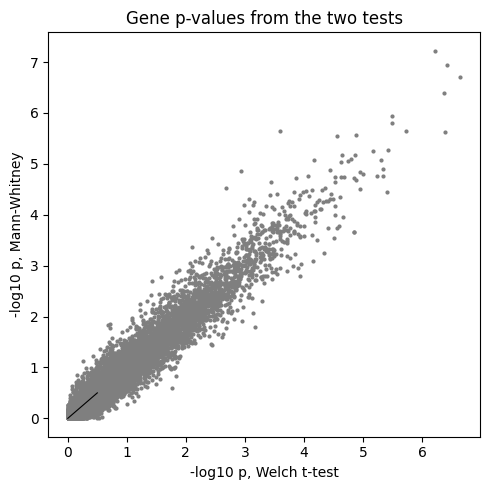

In [24]:
a, b = E.loc[:, died], E.loc[:, ~died]
mw_p = stats.mannwhitneyu(a, b, axis=1, alternative="two-sided").pvalue
mw = pd.DataFrame({"p_MW": mw_p}, index=E.index)
mw["FDR_MW"] = multipletests(mw.p_MW, method="fdr_bh")[1]
both = de.join(mw)
both.to_csv(os.path.join(RES, "annex_A3_mannwhitney.csv"))

sig_t = set(sig.index); sig_mw = set(mw.index[mw.FDR_MW < 0.05])
rho = stats.spearmanr(-np.log10(both.p), -np.log10(both.p_MW)).correlation
print(f"t-test genes (FDR < 0.05): {len(sig_t)}")
print(f"Mann-Whitney genes (FDR < 0.05): {len(sig_mw)}")
print(f"found by both: {len(sig_t & sig_mw)} ({100*len(sig_t & sig_mw)/len(sig_t):.0f}% of the t-test genes)")
print(f"Spearman correlation of -log10 p across all genes: {rho:.3f}")

ratio = a.var(1) / b.var(1)
dfa, dfb = a.shape[1] - 1, b.shape[1] - 1
f_p = 2 * np.minimum(stats.f.cdf(ratio, dfa, dfb), stats.f.sf(ratio, dfa, dfb))
print(f"genes with unequal variances (F-test, FDR < 0.05): {(multipletests(f_p, method='fdr_bh')[1] < 0.05).sum()} of {len(E)}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(-np.log10(both.p), -np.log10(both.p_MW), s=4, c="tab:grey")
lim = max(-np.log10(both.p).max(), -np.log10(both.p_MW).max()) + 0.5
ax.plot([0, lim], [0, lim], c="k", lw=0.8)
ax.set_xlabel("-log10 p, Welch t-test"); ax.set_ylabel("-log10 p, Mann-Whitney")
ax.set_title("Gene p-values from the two tests")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "annex_A3_ttest_vs_mannwhitney.png"), dpi=150); plt.show()